In [3]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nProject files and folders:")
for path in Path.cwd().parent.rglob("tata_elxsi_quarterly*"):
    print(path)

Current working directory:
d:\Business_Performance_Diagnosis\notebooks

Project files and folders:
d:\Business_Performance_Diagnosis\Tata Elxis\tata_elxsi_quarterly_cleaned.csv
d:\Business_Performance_Diagnosis\Tata Elxis\tata_elxsi_quarterly_financials.xlsx
d:\Business_Performance_Diagnosis\Tata Elxis\tata_elxsi_quarterly_financials_xlsx.xlsx
d:\Business_Performance_Diagnosis\data\raw\tata_elxsi_quarterly_cleaned.csv


In [4]:
import pandas as pd

df = pd.read_csv("../data/raw/tata_elxsi_quarterly_cleaned.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (13, 27)


,QuarterDate,Revenue_Cr,Source_YoY_Revenue_Growth,Expenses_Cr,Material_Cost_Ratio,Employee_Cost_Ratio,Operating_Profit_Cr,Source_OPM_Ratio,Other_Income_Cr,Exceptional_Items_Cr,...,Year,Month,Quarter,Calculated_OPM_Ratio,Calculated_Expense_Ratio,Revenue_YoY_Growth,Expenses_YoY_Growth,Operating_Profit_YoY_Growth,OPM_YoY_Change_pp,Revenue_Growth_vs_Source_Diff_pp
0,01-09-2023,882,0.1553,618,0.06,0.54,264,0.30,31,0.0,...,2023,9,Q2,0.299320,0.700680,NaN,NaN,NaN,NaN,NaN
1,01-12-2023,914,0.1180,644,0.05,0.54,270,0.30,35,0.0,...,2023,12,Q3,0.295405,0.704595,NaN,NaN,NaN,NaN,NaN
2,01-03-2024,906,0.0812,645,0.04,0.55,261,0.29,34,0.0,...,2024,3,Q4,0.288079,0.711921,NaN,NaN,NaN,NaN,NaN
3,01-06-2024,926,0.0896,674,0.05,0.54,252,0.27,32,0.0,...,2024,6,Q1,0.272138,0.727862,NaN,NaN,NaN,NaN,NaN
4,01-09-2024,955,0.0832,689,0.06,0.54,266,0.28,64,0.0,...,2024,9,Q2,0.278534,0.721466,0.082766,0.114887,0.007576,-2.07857,-0.043356


In [3]:
import pandas as pd
from pathlib import Path

# Find the CSV file in your project
matches = list(
    Path.cwd().parent.rglob("tata_elxsi_quarterly_cleaned*.csv")
)

if not matches:
    raise FileNotFoundError(
        "CSV not found. Check the data/raw folder and filename."
    )

csv_path = matches[0]
print("Loading file:", csv_path)

# Load dataset and create df
df = pd.read_csv(csv_path)

# Parse dates and sort
df["QuarterDate"] = pd.to_datetime(
    df["QuarterDate"],
    format="%d-%m-%Y",
    errors="coerce"
)

df = df.sort_values("QuarterDate").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Loading file: d:\Business_Performance_Diagnosis\Tata Elxis\tata_elxsi_quarterly_cleaned.csv
Dataset loaded successfully!
Shape: (13, 27)


,QuarterDate,Revenue_Cr,Source_YoY_Revenue_Growth,Expenses_Cr,Material_Cost_Ratio,Employee_Cost_Ratio,Operating_Profit_Cr,Source_OPM_Ratio,Other_Income_Cr,Exceptional_Items_Cr,...,Year,Month,Quarter,Calculated_OPM_Ratio,Calculated_Expense_Ratio,Revenue_YoY_Growth,Expenses_YoY_Growth,Operating_Profit_YoY_Growth,OPM_YoY_Change_pp,Revenue_Growth_vs_Source_Diff_pp
0,2023-09-01,882,0.1553,618,0.06,0.54,264,0.30,31,0.0,...,2023,9,Q2,0.299320,0.700680,NaN,NaN,NaN,NaN,NaN
1,2023-12-01,914,0.1180,644,0.05,0.54,270,0.30,35,0.0,...,2023,12,Q3,0.295405,0.704595,NaN,NaN,NaN,NaN,NaN
2,2024-03-01,906,0.0812,645,0.04,0.55,261,0.29,34,0.0,...,2024,3,Q4,0.288079,0.711921,NaN,NaN,NaN,NaN,NaN
3,2024-06-01,926,0.0896,674,0.05,0.54,252,0.27,32,0.0,...,2024,6,Q1,0.272138,0.727862,NaN,NaN,NaN,NaN,NaN
4,2024-09-01,955,0.0832,689,0.06,0.54,266,0.28,64,0.0,...,2024,9,Q2,0.278534,0.721466,0.082766,0.114887,0.007576,-2.07857,-0.043356


In [4]:
# STEP 2: DATA QUALITY VALIDATION

# 1. Dataset dimensions
print("Dataset dimensions:", df.shape)

# 2. Column names and data types
print("\n--- COLUMN NAMES ---")
print(df.columns.tolist())

print("\n--- DATA TYPES ---")
display(df.dtypes.to_frame(name="Data Type"))

# 3. Missing values
print("\n--- MISSING VALUES ---")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    display(missing.to_frame(name="Missing Count"))

# 4. Duplicate records
print("\n--- DUPLICATE CHECK ---")
print("Duplicate rows:", df.duplicated().sum())
print(
    "Duplicate quarter dates:",
    df["QuarterDate"].duplicated().sum()
)

# 5. Date range
print("\n--- DATE RANGE ---")
print("First quarter:", df["QuarterDate"].min())
print("Last quarter:", df["QuarterDate"].max())

# 6. Check numeric columns for invalid values
print("\n--- NUMERIC SUMMARY ---")
display(df.describe().T)

# 7. Check whether quarter dates are consecutive
print("\n--- QUARTER INTERVAL CHECK ---")
quarter_dates = df["QuarterDate"].sort_values()
quarter_gaps = quarter_dates.diff().dropna().dt.days

print("Days between quarters:")
print(quarter_gaps.tolist())

Dataset dimensions: (13, 27)

--- COLUMN NAMES ---
['QuarterDate', 'Revenue_Cr', 'Source_YoY_Revenue_Growth', 'Expenses_Cr', 'Material_Cost_Ratio', 'Employee_Cost_Ratio', 'Operating_Profit_Cr', 'Source_OPM_Ratio', 'Other_Income_Cr', 'Exceptional_Items_Cr', 'Other_Income_Normal_Cr', 'Interest_Cr', 'Depreciation_Cr', 'PBT_Cr', 'Tax_Ratio', 'Net_Profit_Cr', 'EPS_Rs', 'Year', 'Month', 'Quarter', 'Calculated_OPM_Ratio', 'Calculated_Expense_Ratio', 'Revenue_YoY_Growth', 'Expenses_YoY_Growth', 'Operating_Profit_YoY_Growth', 'OPM_YoY_Change_pp', 'Revenue_Growth_vs_Source_Diff_pp']

--- DATA TYPES ---


,Data Type
QuarterDate,datetime64[us]
Revenue_Cr,int64
Source_YoY_Revenue_Growth,float64
Expenses_Cr,int64
Material_Cost_Ratio,float64
Employee_Cost_Ratio,float64
Operating_Profit_Cr,int64
Source_OPM_Ratio,float64
Other_Income_Cr,int64
Exceptional_Items_Cr,float64



--- MISSING VALUES ---


,Missing Count
Revenue_YoY_Growth,4
Expenses_YoY_Growth,4
Operating_Profit_YoY_Growth,4
OPM_YoY_Change_pp,4
Revenue_Growth_vs_Source_Diff_pp,4



--- DUPLICATE CHECK ---
Duplicate rows: 0
Duplicate quarter dates: 0

--- DATE RANGE ---
First quarter: 2023-09-01 00:00:00
Last quarter: 2026-09-01 00:00:00

--- NUMERIC SUMMARY ---


,count,mean,min,25%,50%,75%,max,std
QuarterDate,13,2025-03-01 18:27:41.538461,2023-09-01 00:00:00,2024-06-01 00:00:00,2025-03-01 00:00:00,2025-12-01 00:00:00,2026-09-01 00:00:00,NaN
Revenue_Cr,13.0,943.384615,882.0,908.0,926.0,955.0,1056.0,51.947952
Source_YoY_Revenue_Growth,13.0,0.068077,-0.0387,0.0152,0.0832,0.118,0.1553,0.067934
Expenses_Cr,13.0,707.923077,618.0,674.0,701.0,731.0,824.0,60.089463
Material_Cost_Ratio,13.0,0.064615,0.04,0.06,0.07,0.07,0.08,0.012659
Employee_Cost_Ratio,13.0,0.563846,0.54,0.54,0.57,0.58,0.59,0.021031
Operating_Profit_Cr,13.0,235.538462,187.0,216.0,245.0,261.0,270.0,28.247759
Source_OPM_Ratio,13.0,0.250769,0.21,0.22,0.25,0.28,0.3,0.034752
Other_Income_Cr,13.0,34.076923,-50.0,34.0,38.0,43.0,64.0,26.87459
Exceptional_Items_Cr,13.0,-7.360769,-95.69,0.0,0.0,0.0,0.0,26.539631



--- QUARTER INTERVAL CHECK ---
Days between quarters:
[91, 91, 92, 92, 91, 90, 92, 92, 91, 90, 92, 92]


In [5]:
import numpy as np
import pandas as pd

# Sort chronologically
df = df.sort_values("QuarterDate").reset_index(drop=True)

# Recalculate core ratios
df["Calculated_OPM_Ratio"] = (
    df["Operating_Profit_Cr"] / df["Revenue_Cr"]
)

df["Calculated_Expense_Ratio"] = (
    df["Expenses_Cr"] / df["Revenue_Cr"]
)

# Recalculate year-over-year growth
# Four rows earlier represents the same quarter in the previous year
for col, source in [
    ("Revenue_YoY_Growth", "Revenue_Cr"),
    ("Expenses_YoY_Growth", "Expenses_Cr"),
    ("Operating_Profit_YoY_Growth", "Operating_Profit_Cr"),
]:
    df[col] = df[source].pct_change(4, fill_method=None) * 100

# Calculate year-over-year margin change in percentage points
df["OPM_YoY_Change_pp"] = (
    df["Calculated_OPM_Ratio"]
    - df["Calculated_OPM_Ratio"].shift(4)
) * 100

# Summary table
kpi_cols = [
    "QuarterDate",
    "Revenue_Cr",
    "Expenses_Cr",
    "Operating_Profit_Cr",
    "Calculated_OPM_Ratio",
    "Calculated_Expense_Ratio",
    "Revenue_YoY_Growth",
    "Expenses_YoY_Growth",
    "Operating_Profit_YoY_Growth",
    "OPM_YoY_Change_pp",
]

display(df[kpi_cols].round(3))

C:\Users\yashg\AppData\Local\Temp\ipykernel_16536\507880917.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df[kpi_cols].round(3))


,QuarterDate,Revenue_Cr,Expenses_Cr,Operating_Profit_Cr,Calculated_OPM_Ratio,Calculated_Expense_Ratio,Revenue_YoY_Growth,Expenses_YoY_Growth,Operating_Profit_YoY_Growth,OPM_YoY_Change_pp
0,2023-09-01,882,618,264,0.299,0.701,NaN,NaN,NaN,NaN
1,2023-12-01,914,644,270,0.295,0.705,NaN,NaN,NaN,NaN
2,2024-03-01,906,645,261,0.288,0.712,NaN,NaN,NaN,NaN
3,2024-06-01,926,674,252,0.272,0.728,NaN,NaN,NaN,NaN
4,2024-09-01,955,689,266,0.279,0.721,8.277,11.489,0.758,-2.079
5,2024-12-01,939,693,247,0.263,0.738,2.735,7.609,-8.519,-3.236
6,2025-03-01,908,701,208,0.229,0.772,0.221,8.682,-20.307,-5.900
7,2025-06-01,892,705,187,0.210,0.790,-3.672,4.599,-25.794,-6.250
8,2025-09-01,918,725,193,0.210,0.790,-3.874,5.225,-27.444,-6.829
9,2025-12-01,953,731,222,0.233,0.767,1.491,5.483,-10.121,-3.010


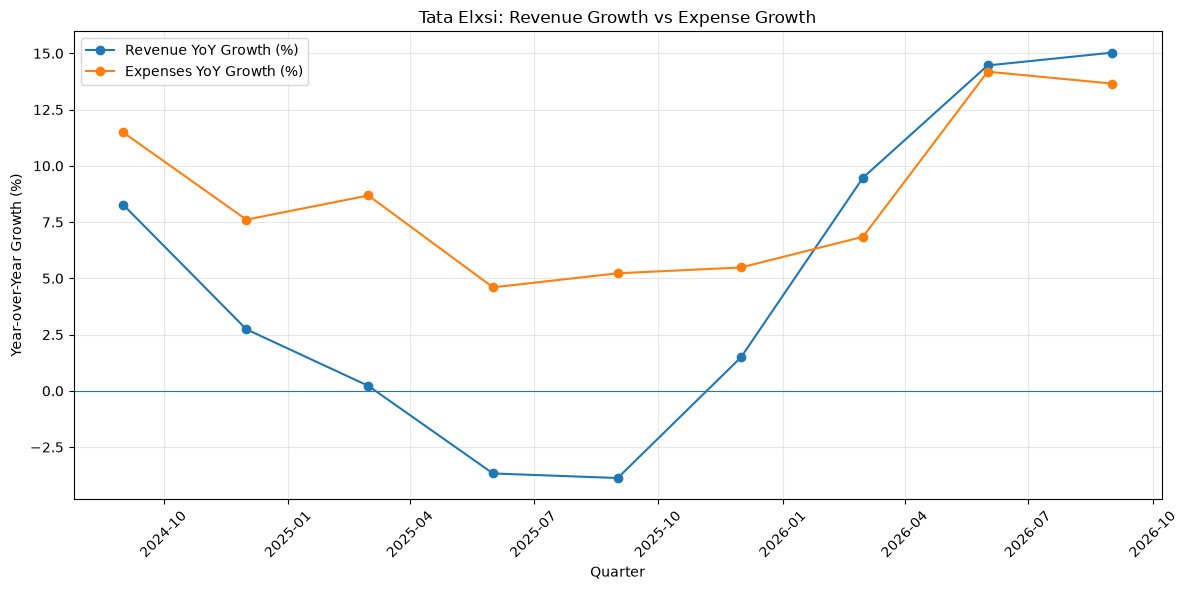

In [6]:
import matplotlib.pyplot as plt

plot_df = df.dropna(
    subset=["Revenue_YoY_Growth", "Expenses_YoY_Growth"]
)

plt.figure(figsize=(12, 6))

plt.plot(
    plot_df["QuarterDate"],
    plot_df["Revenue_YoY_Growth"],
    marker="o",
    label="Revenue YoY Growth (%)"
)

plt.plot(
    plot_df["QuarterDate"],
    plot_df["Expenses_YoY_Growth"],
    marker="o",
    label="Expenses YoY Growth (%)"
)

plt.axhline(0, linewidth=0.8)
plt.title("Tata Elxsi: Revenue Growth vs Expense Growth")
plt.xlabel("Quarter")
plt.ylabel("Year-over-Year Growth (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

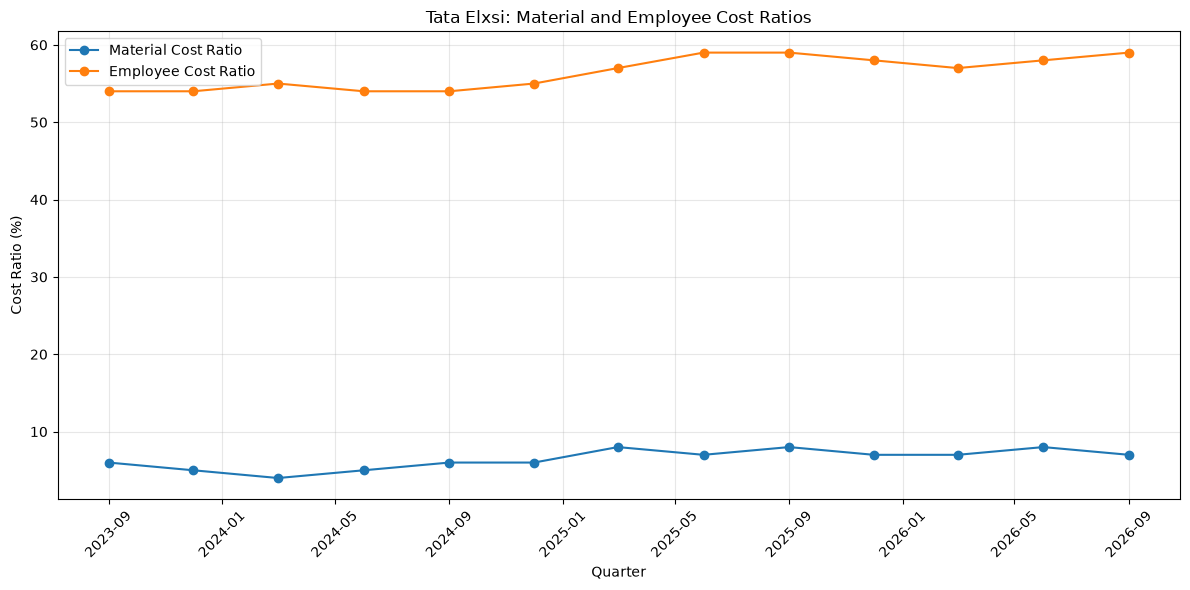

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    df["QuarterDate"],
    df["Material_Cost_Ratio"] * 100,
    marker="o",
    label="Material Cost Ratio"
)

plt.plot(
    df["QuarterDate"],
    df["Employee_Cost_Ratio"] * 100,
    marker="o",
    label="Employee Cost Ratio"
)

plt.title("Tata Elxsi: Material and Employee Cost Ratios")
plt.xlabel("Quarter")
plt.ylabel("Cost Ratio (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
analysis_df = df.dropna(
    subset=["Revenue_YoY_Growth", "Expenses_YoY_Growth"]
).copy()

analysis_df["Growth_Gap_pp"] = (
    analysis_df["Revenue_YoY_Growth"]
    - analysis_df["Expenses_YoY_Growth"]
)

analysis_df["Revenue_per_Expense_Rupee"] = (
    analysis_df["Revenue_Cr"] / analysis_df["Expenses_Cr"]
)

display(
    analysis_df[
        [
            "QuarterDate",
            "Revenue_YoY_Growth",
            "Expenses_YoY_Growth",
            "Growth_Gap_pp",
            "Operating_Profit_YoY_Growth",
            "OPM_YoY_Change_pp",
            "Revenue_per_Expense_Rupee",
        ]
    ].round(2)
)

C:\Users\yashg\AppData\Local\Temp\ipykernel_16536\3692474816.py:25: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,QuarterDate,Revenue_YoY_Growth,Expenses_YoY_Growth,Growth_Gap_pp,Operating_Profit_YoY_Growth,OPM_YoY_Change_pp,Revenue_per_Expense_Rupee
4,2024-09-01,8.28,11.49,-3.21,0.76,-2.08,1.39
5,2024-12-01,2.74,7.61,-4.87,-8.52,-3.24,1.35
6,2025-03-01,0.22,8.68,-8.46,-20.31,-5.90,1.30
7,2025-06-01,-3.67,4.60,-8.27,-25.79,-6.25,1.27
8,2025-09-01,-3.87,5.22,-9.10,-27.44,-6.83,1.27
9,2025-12-01,1.49,5.48,-3.99,-10.12,-3.01,1.30
10,2026-03-01,9.47,6.85,2.62,17.79,1.74,1.33
11,2026-06-01,14.46,14.18,0.28,15.51,0.19,1.27
12,2026-09-01,15.03,13.66,1.38,19.69,0.85,1.28


In [9]:
comparison_dates = [
    "2024-09-01",
    "2025-09-01",
    "2026-09-01",
]

comparison = df[
    df["QuarterDate"].isin(pd.to_datetime(comparison_dates))
].copy()

comparison["Operating_Margin_Pct"] = (
    comparison["Operating_Profit_Cr"]
    / comparison["Revenue_Cr"] * 100
)

comparison["Expense_Ratio_Pct"] = (
    comparison["Expenses_Cr"]
    / comparison["Revenue_Cr"] * 100
)

display(
    comparison[
        [
            "QuarterDate",
            "Revenue_Cr",
            "Expenses_Cr",
            "Operating_Profit_Cr",
            "Operating_Margin_Pct",
            "Expense_Ratio_Pct",
            "Employee_Cost_Ratio",
            "Material_Cost_Ratio",
        ]
    ].round(2)
)

C:\Users\yashg\AppData\Local\Temp\ipykernel_16536\2145852342.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,QuarterDate,Revenue_Cr,Expenses_Cr,Operating_Profit_Cr,Operating_Margin_Pct,Expense_Ratio_Pct,Employee_Cost_Ratio,Material_Cost_Ratio
4,2024-09-01,955,689,266,27.85,72.15,0.54,0.06
8,2025-09-01,918,725,193,21.02,78.98,0.59,0.08
12,2026-09-01,1056,824,231,21.88,78.03,0.59,0.07


In [10]:
from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "tata_elxsi_quarterly_kpis.csv"

df.to_csv(output_path, index=False)

print("Exported to:", output_path.resolve())
print("Rows exported:", len(df))

Exported to: D:\Business_Performance_Diagnosis\data\processed\tata_elxsi_quarterly_kpis.csv
Rows exported: 13
